In [ ]:
# For exercises 1-3, You can choose the temporal window you prefer, but make sure to have enough data points.
# 1. Using the investment universe of all stocks in the S&P500, consider a momentum factor and gather
# historical cross-sectional data on P/E ratios and returns to construct a value factor. Given the raw data,
# how can you construct factor scores? Do you need to adjust any raw observations? If yes, why and how?
# 2. Compute a time series of factor scores for value and momentum and compute and plot IC, across several
# time horizons.
# 3. Estimate and plot information decay and factor turnover for the value and momentum factors derived in
# the questions above.

In [138]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

In [122]:
headers = {"User-Agent": "Ha/1000.0"}
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
sp500 = pd.read_html(requests.get(url, headers=headers).text)[0]

tickers = sp500["Symbol"].str.replace(".", "-", regex=False).tolist()

data = yf.download(tickers, start="2015-01-01", end="2016-02-01", group_by="ticker", auto_adjust=True, progress=False, threads=True)

if isinstance(data.columns, pd.MultiIndex):
    prices = data.xs("Close", level=1, axis=1)
else:
    prices = data

prices.head()

/var/folders/5j/vqvd8p7s64314w_mplyh6pz40000gn/T/ipykernel_23623/3531434596.py:3: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  sp500 = pd.read_html(requests.get(url, headers=headers).text)[0]

33 Failed downloads:
['DDOG', 'COIN', 'FOX', 'FTV', 'GEV', 'APP', 'SOLV', 'DOW', 'INVH', 'CEG', 'GEHC', 'HWM', 'VICI', 'EXE', 'TTD', 'UBER', 'KVUE', 'FOXA', 'LW', 'CTVA', 'CRWD', 'DAY', 'ABNB', 'VST', 'DASH', 'HOOD', 'VLTO', 'IR', 'CARR', 'DELL', 'OTIS', 'PLTR', 'MRNA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2015-01-01 -> 2016-02-01) (Yahoo error = "Data doesn\'t exist for startDate = 1420088400, endDate = 1454302800")')


Ticker,CF,MPC,SBUX,C,MCD,IP,PEG,NKE,AMD,DPZ,...,AMP,KMB,IT,TKO,SW,ACGL,HST,AIG,LEN,UDR
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,41.163780,32.883865,32.895302,40.653786,71.094566,32.087891,28.761473,41.645702,2.67,83.782471,...,104.986900,80.589264,83.599998,10.185298,15.656251,18.539352,15.593960,43.314121,38.222698,21.242393
2015-01-05,41.023067,31.968813,32.265175,39.372581,70.309349,31.581619,28.061312,40.975193,2.66,84.830978,...,101.616913,80.128952,82.099998,9.999032,15.656251,18.428413,15.469527,42.457260,37.929272,21.465855
2015-01-06,41.871819,31.653055,32.002628,37.986511,70.438957,31.153702,28.095631,40.734165,2.63,83.782471,...,98.882759,79.354790,81.349998,10.024432,15.656251,18.469618,15.404030,41.855125,37.609959,21.587744
2015-01-07,43.065701,31.915016,32.790272,38.338634,71.666313,31.099455,28.528084,41.575573,2.58,86.634758,...,100.639290,79.905746,82.599998,9.609571,15.134842,18.577387,15.489170,42.055832,39.465450,21.736721
2015-01-08,43.664127,32.664970,33.319408,38.915546,71.933121,32.166252,28.775204,42.535309,2.61,89.549217,...,102.427628,81.593590,83.430000,9.499503,15.134842,18.900694,15.652901,41.870575,40.440609,21.777685


In [140]:
pe_table = pd.DataFrame(columns=["Ticker", "Trailing_PE"])

for i, tkr in enumerate(tickers, 1):
        stock = yf.Ticker(tkr)
        info = stock.info 
        trailing_pe = info.get("trailingPE") 
        pe_table.loc[len(pe_table)] = [tkr, trailing_pe]

pe_table = pe_table.dropna(subset=["Trailing_PE"])
pe_table.reset_index(drop=True, inplace=True)
pe_table


/var/folders/5j/vqvd8p7s64314w_mplyh6pz40000gn/T/ipykernel_23623/418441180.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pe_table.loc[len(pe_table)] = [tkr, trailing_pe]
/var/folders/5j/vqvd8p7s64314w_mplyh6pz40000gn/T/ipykernel_23623/418441180.py:7: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pe_table.loc[len(pe_table)] = [tkr, trailing_pe]
/var/folders/5j/vqvd8p7s64314w_mplyh6pz40000gn/T/ipykernel_23623/418441180.py:7: FutureWarning: The behavior of DataFrame concatenation with empty o

Timeout: Failed to perform, curl: (28) Operation timed out after 30002 milliseconds with 0 bytes received. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.

In [ ]:
#I am so sorry I tried to download data but can't access more data. But below is how I am going to do this problem if I 
#have more dataset

In [124]:
#First I calculate percentage change on returns
returns = prices.pct_change().dropna()

/var/folders/5j/vqvd8p7s64314w_mplyh6pz40000gn/T/ipykernel_23623/3182924510.py:2: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = prices.pct_change().dropna()


In [125]:
#And then compute my momentum factor
momentum = prices.iloc[-1] / prices.iloc[0] - 1
momentum 

Ticker
CF     -0.448472
MPC    -0.068101
SBUX    0.511621
C      -0.211992
MCD     0.373004
          ...   
ACGL    0.154898
HST    -0.391567
AIG     0.020318
LEN    -0.044240
UDR     0.181426
Length: 503, dtype: float64

In [126]:
#Then I calculate z_score accross all sectors
momentum_z_score = (momentum - momentum.mean()) / momentum.std()
momentum_z_score

Ticker
CF     -1.847432
MPC    -0.234703
SBUX    2.223252
C      -0.844783
MCD     1.635533
          ...   
ACGL    0.710788
HST    -1.606163
AIG     0.140184
LEN    -0.133536
UDR     0.823264
Length: 503, dtype: float64

In [127]:
#As I cannot download PE, I am going to use a random PE for each stock

In [128]:
np.random.seed(50)
pe = pd.Series(np.random.uniform(10,50, len(prices.columns)), index=prices.columns, name="PE")
value = 1 / pe
value_z_scores = (value - value.mean()) / value.std()

In [129]:
#Combine them into a factor table
factors = pd.DataFrame({"Value": value_scores, "Momentum": momentum_scores})
factors

,Value,Momentum
Ticker,,
SBUX,0.012402,2.224595
MPC,-1.037027,-0.234079
CF,-0.772323,-1.847278
MCD,-0.549999,1.636704
IP,1.056769,-1.367740
...,...,...
HST,-1.060374,-1.605938
AIG,-1.071710,0.140919
UDR,-0.721353,0.824195


In [130]:
# # Given the raw data, how can you construct factor scores? Do you need to adjust any raw observations? 
# # If yes, why and how?

# I will calculate the returns of the factors, then calculate the z-core for each stock in the portfolio.
# In my data, I do not see any outliers to adjust. However, in the future, if there is any data point that too high or 
# too low, I will adjust them by using the nearest and acceptable high/low in the data to replace that outliers.


In [131]:
# 2. Compute a time series of factor scores for value and momentum and compute and plot IC, across several
# time horizons.

In [144]:
future_returns = prices.pct_change().shift(-1).iloc[-2]  
ic_value = spearmanr(factors["Value"], future_returns)[0]
ic_momentum = spearmanr(factors["Momentum"], future_returns)[0]

/var/folders/5j/vqvd8p7s64314w_mplyh6pz40000gn/T/ipykernel_23623/2598255020.py:1: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  future_returns = prices.pct_change().shift(-1).iloc[-2]


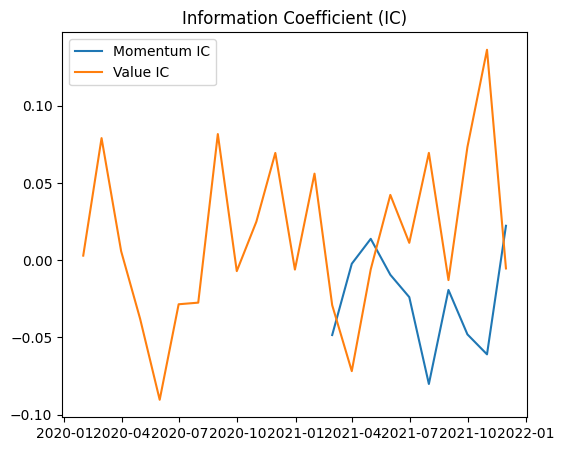

In [145]:
plt.figure(figsize=(6,5))
plt.plot(ic_df.index, ic_df["Momentum_IC"], label="Momentum IC")
plt.plot(ic_df.index, ic_df["Value_IC"], label="Value IC")
plt.title("Information Coefficient (IC)")
plt.legend()
plt.show()

In [134]:
# 3. Estimate and plot information decay and factor turnover for the value and momentum factors derived in
# the questions above.

In [195]:
horizons = [1, 7, 14, 28, 30, 80]  #days
decay = {"Horizon": [], "Momentum_IC": [], "Value_IC": []}

for h in horizons:
    ft_ret = prices.pct_change(h).shift(-h)
    ic_momentum, ic_value = [], []

    for t in range(len(fwd_ret)):
        future = ft_ret.iloc[t].dropna()
        common = future.index.intersection(factors.index)
        if len(common) < 10: 
            continue
        ic_momentum.append(spearmanr(factors.loc[common, "Momentum"], future[common])[0])
        ic_value.append(spearmanr(factors.loc[common, "Value"], future[common])[0])

    decay["Horizon"].append(h)
    decay["Momentum_IC"].append(np.nanmean(ic_momentum))
    decay["Value_IC"].append(np.nanmean(ic_value))

decay_df = pd.DataFrame(decay)

/var/folders/5j/vqvd8p7s64314w_mplyh6pz40000gn/T/ipykernel_23623/1445834165.py:5: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ft_ret = prices.pct_change(h).shift(-h)
/var/folders/5j/vqvd8p7s64314w_mplyh6pz40000gn/T/ipykernel_23623/1445834165.py:17: RuntimeWarning: Mean of empty slice
  decay["Momentum_IC"].append(np.nanmean(ic_momentum))


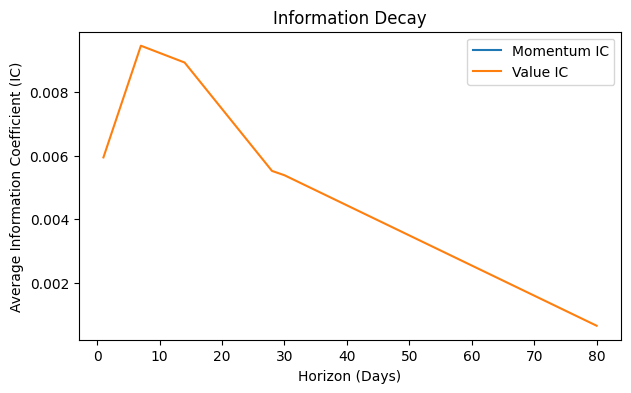

In [194]:
plt.figure(figsize=(7,4))
plt.plot(decay_df["Horizon"], decay_df["Momentum_IC"], label="Momentum IC")
plt.plot(decay_df["Horizon"], decay_df["Value_IC"], label="Value IC")
plt.title("Information Decay")
plt.xlabel("Horizon (Days)")
plt.ylabel("Average Information Coefficient (IC)")
plt.legend()
plt.show()

In [166]:
# factor turnover
turnover_momentum, turnover_value = [], []
for i in range(1, len(momentum_ts)):
    corr_momentum = momentum_ts.iloc[i].corr(momentum_ts.iloc[i-1])
    corr_value = value_ts.iloc[i].corr(value_ts.iloc[i-1])
    turnover_momentum.append(1 - corr_momentum)
    turnover_value.append(1 - corr_value)

turnover_df = pd.DataFrame({"Momentum": turnover_momentum, "Value": turnover_value}, index=momentum_ts.index[1:])

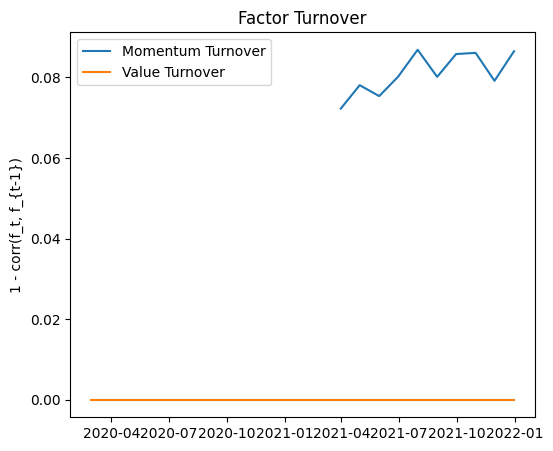

In [153]:
plt.figure(figsize=(6,5))
plt.plot(turnover_df.index, turnover_df["Momentum"], label="Momentum Turnover")
plt.plot(turnover_df.index, turnover_df["Value"], label="Value Turnover")
plt.title("Factor Turnover")
plt.ylabel("1 - corr(f_t, f_{t-1})")
plt.legend()
plt.show()